In [9]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt

In [3]:
# 1a
def tpeak(x, D):
    return (1/4)*(-1 + np.sqrt(1 + ((4*x**2)/D)))

xs = np.array([0.1,1,10])
D = 1

tpeak(xs, D)

array([0.00495098, 0.30901699, 4.7562461 ])

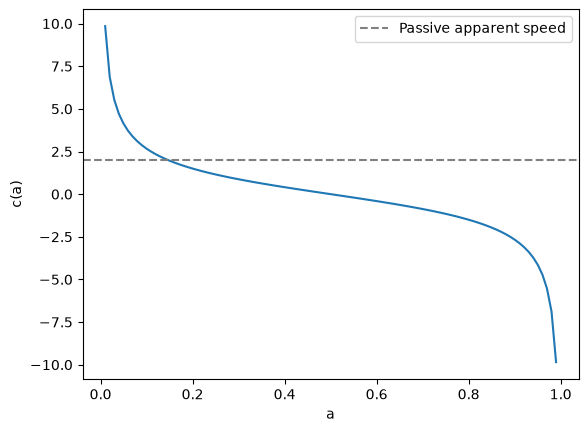

In [6]:
# 1c

D = 1
def c(a, D):
    return np.sqrt(D)*((1-2*a)/np.sqrt(a*(1-a)))

a = np.linspace(0.01, 0.99, 100)
plt.plot(a, c(a, D))
plt.axhline(2*np.sqrt(D), color="gray", ls="--", label="Passive apparent speed")
plt.xlabel("a")
plt.ylabel("c(a)")
plt.legend()
plt.show()


In [8]:
# 2a
def tau(C, g_L, g_e, g_i):
    return C/(g_L + g_e + g_i)

C = 200

print(tau(C, 10, 0, 0))
print(tau(C, 10, 20, 20))

20.0
4.0


root: [-26.95680401]


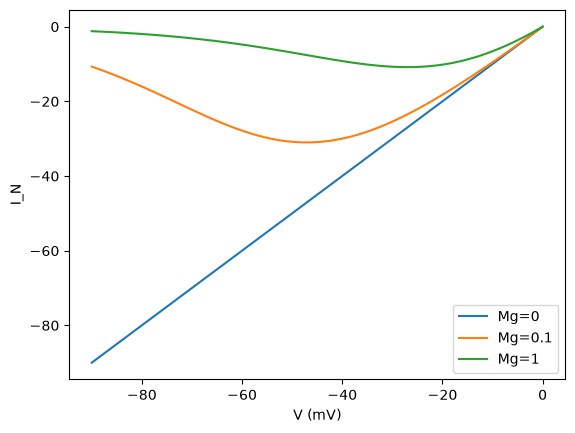

In [16]:
# 2c

def B(V, Mg, V0):
    return 1/(1 + (Mg/3.57)*np.exp(-V/V0))

def slope(V, E_N, Mg, V0):
    return 1+((V-E_N)*(1-B(V, Mg, V0))/V0)

E_N, Mg, V0 = 0, 1, 16.13

print("root:", opt.root(slope, x0=0, args=(E_N, Mg, V0)).x)

def I_N(V, E_N, Mg, V0):
    return (V-E_N)*B(V, Mg, V0)

V = np.linspace(-90,0, 100)
plt.plot(V, I_N(V, E_N, 0, V0), label="Mg=0")
plt.plot(V, I_N(V, E_N, 0.1, V0), label="Mg=0.1")
plt.plot(V, I_N(V, E_N, 1, V0), label="Mg=1")
plt.xlabel("V (mV)")
plt.ylabel("I_N")
plt.legend()
plt.show()

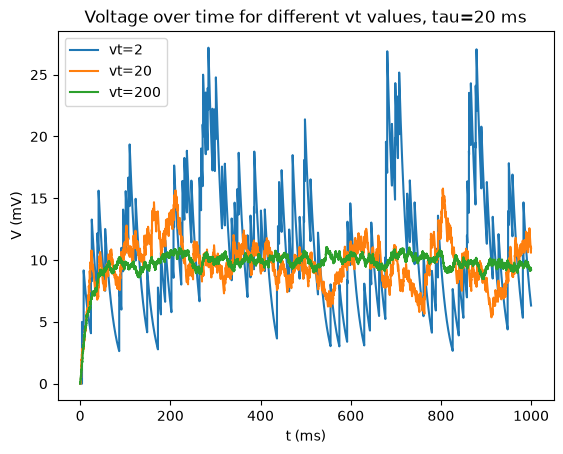

     vt        v        w    tau | mean (theory) mean (sim) | var (theory)  var (sim) | skew (theory) skew (sim)
----------------------------------------------------------------------------------------------------------------
      2    0.100    5.000     20 |        10.000    10.7735 |       25.000    24.8750 |        0.6667     0.6685
     20    1.000    0.500     20 |        10.000     9.6708 |        2.500     3.6980 |        0.2108    -0.3481
    200   10.000    0.050     20 |        10.000     9.7033 |        0.250     1.1762 |        0.0667    -4.7803


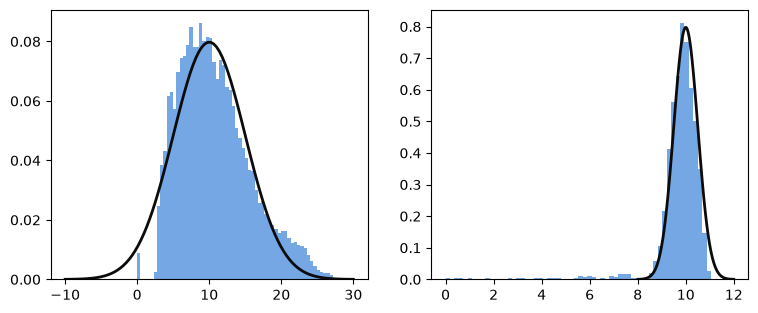

In [79]:
# 4d

# Simulate dynamics using forward Euler method
def dVdt(V, tau, w, v, ds):
    n_spike = np.random.poisson(v*ds)
    return -ds*(V/tau) + (w * n_spike)

vts = np.array([2,20,200])
mean_V = 10
tau = 20

T = 1000
dt = np.linspace(0, T, 100000)
ds = dt[1]-dt[0]
Vs = []

for vt in vts:
    w = mean_V/vt
    v = vt/tau
    V = np.zeros_like(dt)

    for i in range(len(dt)):

        V[i] = V[i-1] + dVdt(V[i-1], tau, w, v, ds)

    Vs.append(V)
    plt.plot(dt, V, label=f"vt={vt}")
    plt.legend()

# Plot voltage traces
plt.xlabel("t (ms)")
plt.ylabel("V (mV)")
plt.title(f"Voltage over time for different vt values, tau={tau} ms")
plt.show()

# Print summary table
hdr = (f"{'vt':>7} {'v':>8} {'w':>8} {'tau':>6} | "
       f"{'mean (theory)':>13} {'mean (sim)':>10} | "
       f"{'var (theory)':>12} {'var (sim)':>10} | {'skew (theory)':>13} {'skew (sim)':>10}")
print(hdr)
print("-" * len(hdr))
for (i, vt) in enumerate(vts):
    V = Vs[i]
    w = mean_V/vt
    v = vt/tau
    m_theory = mean_V
    v_theory = (mean_V*w)/2
    s_theory = 2*np.sqrt(2)/(3*np.sqrt(vt))
    m_sim = np.mean(V)
    v_sim = np.var(V)
    s_sim = (np.mean((V-m_sim)**3)/v_sim**(3/2))

    print(f"{vt:7.0f} {v:8.3f} {w:8.3f} {tau:6.0f} | "
          f"{m_theory:13.3f} {m_sim:10.4f} | "
          f"{v_theory:12.3f} {v_sim:10.4f} | {s_theory:13.4f} {s_sim:10.4f}")

# Plot voltage histograms against Gaussian
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

for ax, vt_i, vt in zip(axes, [0, 2], [2, 200]):
    V = Vs[vt_i]
    w = mean_V/vt
    v_theory = (mean_V*w)/2
    x = np.linspace(mean_V-4*np.sqrt(v_theory), mean_V+4*np.sqrt(v_theory), 100)

    ax.hist(V, 60, density=True, color="#2a78d6", alpha=.65, label="simulated")
    ax.plot(x, np.exp(-(x-mean_V)**2/(2*v_theory))/(np.sqrt(v_theory)*np.sqrt(2*np.pi)),
                     color="#0b0b0b", lw=2, label="Gaussian")

In [72]:
# 5b
def time_below_reset(mu, thetha, sig2):
    return (sig2/(mu*thetha))*(1-np.exp(-(mu*thetha)/sig2))

mu, theta = 1,1
sig2 = np.array([0.25,1,4])

print(time_below_reset(mu, theta, sig2))

[0.24542109 0.63212056 0.88479687]


   sig2 | rate (theory) rate (sim) | frac u<0 (theory) frac u<0 (sim)
---------------------------------------------------------------------
   0.25 |         1.000     1.0111 |             0.245         0.2332
   1.00 |         1.000     0.9378 |             0.632         0.6320
   4.00 |         1.000     0.8900 |             0.885         0.8840


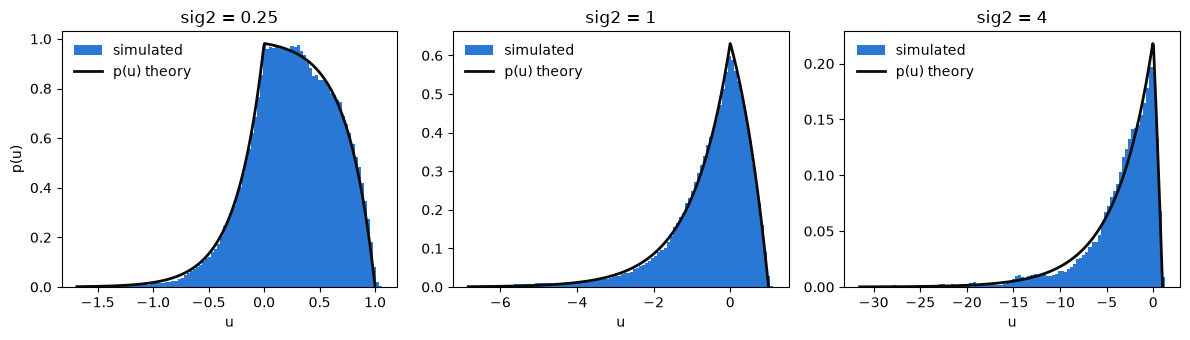

In [109]:
# 5c

# Simulate dynamics using Euler Maruyama method
def dudt(mu, dt, sig2):
    noise = np.random.normal(0, np.sqrt(dt))
    return dt*mu + np.sqrt(2*sig2)*noise

mu, theta = 1, 1
sig2s = [0.25, 1, 4]
T = (mu/theta)*1000
transient_frac = 10
dt = np.linspace(0, T, 1000000)
ds = dt[1]-dt[0]
us = []

for sig2 in sig2s:
    u = np.zeros_like(dt)

    for i in range(len(dt)):
        u[i] = u[i-1] + dudt(mu, ds, sig2)

        if u[i-1] >= theta:
            u[i] = 0

    u = u[len(u)//transient_frac:]  # Discard initial transient to focus on steady-state behavior
    us.append(u)

# Print summary table
hdr = (f"{'sig2':>7} | {'rate (theory)':>13} {'rate (sim)':>10} | "
       f"{'frac u<0 (theory)':>17} {'frac u<0 (sim)':>14}")
print(hdr)
print("-" * len(hdr))
for (i, sig2) in enumerate(sig2s):
    u = us[i]
    r_theory = mu/theta
    r_sim = np.count_nonzero(u[:-1] >= theta)/(T - T/transient_frac)
    f_theory = time_below_reset(mu, theta, sig2)
    f_sim = np.mean(u < 0)

    print(f"{sig2:7.2f} | {r_theory:13.3f} {r_sim:10.4f} | "
          f"{f_theory:17.3f} {f_sim:14.4f}")

# Plot voltage histograms against the stationary density p(u)
def p_theory(u, mu, theta, sig2):
    nu = mu/theta
    below  = (1 - np.exp(-mu*theta/sig2))*np.exp(mu*np.minimum(u, 0)/sig2)
    inside = 1 - np.exp(mu*(np.clip(u, 0, theta) - theta)/sig2)
    return (nu/mu)*np.where(u < 0, below, np.where(u <= theta, inside, 0.0))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, sig2_i, sig2 in zip(axes, [0, 1, 2], sig2s):
    u = us[sig2_i]
    x = np.linspace(u.min(), theta, 400)

    ax.hist(u, 100, density=True, color="#2a78d6", label="simulated")
    ax.plot(x, p_theory(x, mu, theta, sig2), color="#0b0b0b", lw=2, label="p(u) theory")
    ax.set_title(f"sig2 = {sig2}")
    ax.set_xlabel("u")
    ax.legend(frameon=False)

axes[0].set_ylabel("p(u)")
plt.tight_layout()
plt.show()
